# Atendimento por redes de água e esgoto no Brasil em 2024

**Guilherme Daflon Goulart Costa (RA 1015071) e Marcella Guimaraes Rodrigues Da Silva (RA 1015652)**  
**Centro Universitário La Salle do Rio de Janeiro** · Bacharelado em Sistemas de Informação, 6º período  
**Linguagens de Programação · 2026.2** · Professor Alexandre Neves Louzada

Projeto Prático G2. Fonte: [Resultados SINISA 2025](https://www.gov.br/cidades/pt-br/acesso-a-informacao/acoes-e-programas/saneamento/sinisa/resultados-sinisa/resultados-sinisa-2025), ano de referência 2024.

Este notebook é a análise exploratória do projeto. Ele roda o ETL, confere a qualidade dos dados e responde às três perguntas de pesquisa, na mesma ordem do [artigo](https://gdaflon.github.io/lasalle/projeto-saneamento-sinisa/).

1. **RQ1** — Como a diferença entre os indicadores totais de água e esgoto varia entre macrorregiões e UFs?
2. **RQ2** — Quanto o atendimento urbano difere do rural em cada serviço?
3. **RQ3** — Nos municípios com ambos os indicadores válidos, qual é a dispersão das diferenças e como os dois indicadores se associam?

As metas citadas (99% em água e 90% em esgoto até 2033) vêm do art. 11-B da Lei nº 11.445/2007, incluído pela Lei nº 14.026/2020. Elas servem de régua: a meta de esgoto soma coleta e tratamento, e os indicadores daqui medem atendimento por rede.

## 1. Carregamento e tratamento

No ambiente local, execute a partir da raiz do projeto ou da pasta `notebooks/`. No Colab, a célula busca os scripts e os quatro XLSX no repositório público. O ETL valida os arquivos por SHA-256, localiza os cabeçalhos pelos códigos dos indicadores, trata os marcadores de ausência e grava CSV, Parquet e a auditoria.

In [1]:
from importlib.util import find_spec
from pathlib import Path
from urllib.request import urlretrieve
import subprocess
import sys

pasta_atual = Path.cwd()
raiz = next((p for p in (pasta_atual, pasta_atual.parent) if (p / "src/etl.py").is_file()), None)

if raiz is None:
    raiz = pasta_atual / "projeto-saneamento-sinisa"
    remoto = "https://raw.githubusercontent.com/GDaflon/lasalle/main/linguagens-de-programacao/projeto-saneamento-sinisa"
    arquivos = [
        "src/__init__.py", "src/etl.py", "src/analise.py",
        "data/raw/agua_municipal.xlsx", "data/raw/agua_uf.xlsx",
        "data/raw/esgoto_municipal.xlsx", "data/raw/esgoto_uf.xlsx",
    ]
    for arquivo in arquivos:
        destino = raiz / arquivo
        if not destino.exists():
            destino.parent.mkdir(parents=True, exist_ok=True)
            parcial = destino.with_suffix(".part")
            urlretrieve(f"{remoto}/{arquivo}", parcial)
            parcial.replace(destino)
    faltantes = [pacote for pacote in ("openpyxl==3.1.5", "pyarrow==26.0.1")
                 if find_spec(pacote.split("==")[0]) is None]
    if faltantes:
        subprocess.check_call([sys.executable, "-m", "pip", "install", *faltantes])

sys.path.insert(0, str(raiz))
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src.etl import executar
from src import analise as an

pd.set_option("display.max_rows", 40)
pd.set_option("display.float_format", lambda valor: f"{valor:.2f}")

saida = raiz / "data/processed"
executar(raiz / "data/raw", saida)
municipios, territorios = an.carregar(saida)
auditoria = json.loads((saida / "auditoria.json").read_text(encoding="utf-8"))

### 1.1 Estrutura das tabelas tratadas

`municipios` tem uma linha por código IBGE da união das duas bases. `territorios` tem os consolidados oficiais: Brasil, cinco macrorregiões e 27 UFs. Os tipos abaixo vêm do Parquet, que preserva o IBGE como texto e a capital como booleano.

In [2]:
print(f"municipios: {municipios.shape[0]} linhas × {municipios.shape[1]} colunas")
print(f"territorios: {territorios.shape[0]} linhas × {territorios.shape[1]} colunas")
display(municipios.dtypes.rename("tipo").to_frame().T)
display(municipios.head())
display(territorios.head(6))

municipios: 5149 linhas × 15 colunas
territorios: 33 linhas × 14 colunas


,ibge,regiao,municipio,uf,capital,prestador_agua,prestador_esgoto,presenca,agua_total_pct,agua_urbana_pct,agua_rural_pct,esgoto_total_pct,esgoto_urbana_pct,esgoto_rural_pct,diferenca_total_pp
tipo,string[python],object,object,object,bool,string[python],string[python],category,float64,float64,float64,float64,float64,float64,float64


,ibge,regiao,municipio,uf,capital,prestador_agua,prestador_esgoto,presenca,agua_total_pct,agua_urbana_pct,agua_rural_pct,esgoto_total_pct,esgoto_urbana_pct,esgoto_rural_pct,diferenca_total_pp
0,1100015,Norte,Alta Floresta D Oeste,RO,False,Autarquia,<NA>,Somente água,60.35,100.00,0.00,NaN,NaN,NaN,NaN
1,1100023,Norte,Ariquemes,RO,False,Empresa privada,Empresa privada,Ambos,86.70,100.00,0.00,24.07,27.76,0.00,62.63
2,1100031,Norte,Cabixi,RO,False,Sociedade de economia mista,<NA>,Somente água,46.06,86.59,0.00,NaN,NaN,NaN,NaN
3,1100049,Norte,Cacoal,RO,False,Autarquia,Autarquia,Ambos,82.76,100.00,0.00,64.55,78.00,0.00,18.21
4,1100056,Norte,Cerejeiras,RO,False,Sociedade de economia mista,Município,Ambos,65.96,74.24,0.00,100.00,100.00,100.00,-34.04


,nivel,sigla,territorio,regiao,agua_total_pct,agua_urbana_pct,agua_rural_pct,esgoto_total_pct,esgoto_urbana_pct,esgoto_rural_pct,esgoto_tratado_pct,diferenca_total_pp,hiato_agua_pp,hiato_esgoto_pp
0,Brasil,BR,Brasil,None,84.14,92.32,22.88,62.30,68.44,4.75,85.16,21.84,69.44,63.69
1,Macrorregião,N,Norte,None,62.81,74.93,13.27,24.65,27.68,1.05,90.64,38.16,61.66,26.63
2,Macrorregião,NE,Nordeste,None,73.70,85.34,29.86,35.90,43.45,2.81,81.36,37.80,55.48,40.64
3,Macrorregião,SE,Sudeste,None,92.11,96.18,21.42,81.94,85.80,11.23,82.76,10.17,74.76,74.57
4,Macrorregião,S,Sul,None,88.32,97.51,17.22,57.72,63.32,2.74,94.64,30.60,80.29,60.58
5,Macrorregião,CO,Centro-Oeste,None,89.71,96.95,9.44,68.31,73.28,2.73,95.58,21.40,87.51,70.55


### 1.2 Auditoria: ausências, zeros e presença nos módulos

Nenhum valor é imputado. Os textos "Não calculado" das planilhas viram ausente, e os zeros publicados continuam como valores válidos. A tabela mostra quantos registros cada indicador tem em cada situação.

In [3]:
presenca = municipios["presenca"].value_counts().rename_axis("Presença").rename("Municípios")
print(f"União: {len(municipios)} códigos IBGE")
display(presenca.to_frame())

registros = []
for arquivo, detalhes in auditoria.items():
    if arquivo.endswith("_municipal.xlsx"):
        for variavel, contagens in detalhes["indicadores"].items():
            registros.append({
                "arquivo": arquivo,
                "variável": variavel,
                "linhas": detalhes["linhas"],
                "válidos": contagens["validos"],
                "zeros válidos": contagens["zeros"],
                "sem cálculo": sum(contagens["marcadores"].values()),
            })
display(pd.DataFrame(registros))

União: 5149 códigos IBGE


,Municípios
Presença,
Ambos,2744
Somente água,2400
Somente esgoto,5


,arquivo,variável,linhas,válidos,zeros válidos,sem cálculo
0,agua_municipal.xlsx,agua_rural_pct,5144,5089,2076,55
1,agua_municipal.xlsx,agua_total_pct,5144,5118,33,26
2,agua_municipal.xlsx,agua_urbana_pct,5144,5095,42,49
3,esgoto_municipal.xlsx,esgoto_rural_pct,2749,2698,1710,51
4,esgoto_municipal.xlsx,esgoto_total_pct,2749,2728,5,21
5,esgoto_municipal.xlsx,esgoto_urbana_pct,2749,2724,18,25


In [4]:
display(municipios.isna().sum().rename("ausentes").to_frame().T)
display(pd.DataFrame({
    "água": pd.Series(auditoria["agua_municipal.xlsx"]["prestadores"]),
    "esgoto": pd.Series(auditoria["esgoto_municipal.xlsx"]["prestadores"]),
}).fillna(0).astype(int).rename_axis("Natureza do prestador"))

,ibge,regiao,municipio,uf,capital,prestador_agua,prestador_esgoto,presenca,agua_total_pct,agua_urbana_pct,agua_rural_pct,esgoto_total_pct,esgoto_urbana_pct,esgoto_rural_pct,diferenca_total_pp
ausentes,0,0,0,0,0,5,2400,0,31,54,60,2421,2425,2451,2439


,água,esgoto
Natureza do prestador,,
Associação privada,13,1
Autarquia,485,316
Empresa privada,978,600
Empresa pública,51,45
Mais de um tipo,313,221
Município,617,587
Sociedade de economia mista,2687,979


As planilhas municipais têm 5.144 registros de água e 2.749 de esgoto. Dos 2.744 códigos presentes nas duas, 34 ficam fora da comparação pareada por ausência em pelo menos um indicador total. Restam **2.710 pares válidos**.

### 1.3 Quem entra na amostra pareada

A base de esgoto cobre bem menos municípios que a de água, e a cobertura muda de região para região. Antes de analisar os pares, vale medir esse desequilíbrio.

,municipios,agua_valida,esgoto_valido,pares,pares_pct
regiao,,,,,
Norte,393,391,62,62,15.80
Nordeste,1528,1516,582,573,37.50
Sudeste,1626,1612,1446,1439,88.50
Sul,1158,1156,445,444,38.30
Centro-Oeste,444,443,193,192,43.20
Brasil,5149,5118,2728,2710,52.60


,Mediana do indicador de água (%)
mediana_agua_pareados,81.38
mediana_agua_fora,62.72
mediana_agua_todos,73.19


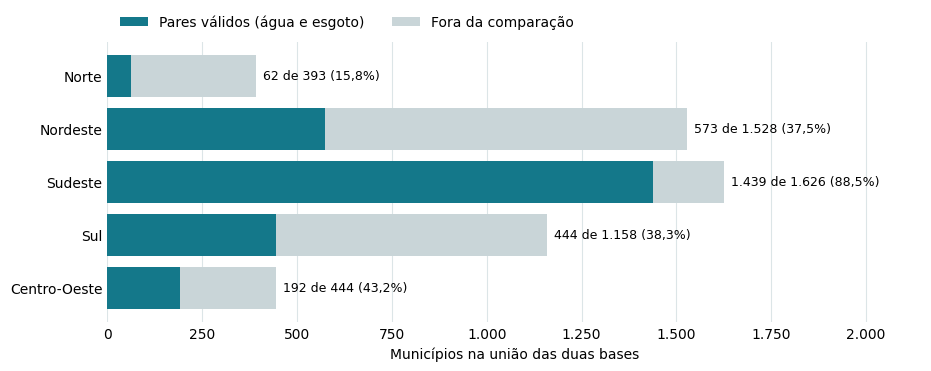

In [5]:
display(an.cobertura(municipios).round(1))
display(pd.Series(an.vies_de_selecao(municipios), name="Mediana do indicador de água (%)").round(2).to_frame())
figura = an.grafico_cobertura(municipios)
display(figura)
plt.close(figura)

O Sudeste tem 88,5% dos municípios na amostra pareada, e o Norte, 15,8%. A seleção também não é neutra: a mediana do indicador de água é de 81,4% nos municípios pareados e de 62,7% nos que ficam de fora. Os resultados municipais (RQ3) descrevem o conjunto observado e tendem a subestimar as diferenças do país. RQ1 e RQ2 usam os consolidados oficiais e não dependem dessa amostra.

## 2. RQ1 — Diferenças entre regiões e UFs

A diferença em pontos percentuais é `água total − esgoto total`. Os valores nacionais e regionais são os consolidados do SINISA, calculados com as regras e as bases de cada módulo.

,territorio,agua_total_pct,esgoto_total_pct,diferenca_total_pp,esgoto_tratado_pct
0,Brasil,84.14,62.30,21.84,85.16
1,Norte,62.81,24.65,38.16,90.64
2,Nordeste,73.70,35.90,37.80,81.36
3,Sudeste,92.11,81.94,10.17,82.76
4,Sul,88.32,57.72,30.60,94.64
5,Centro-Oeste,89.71,68.31,21.40,95.58


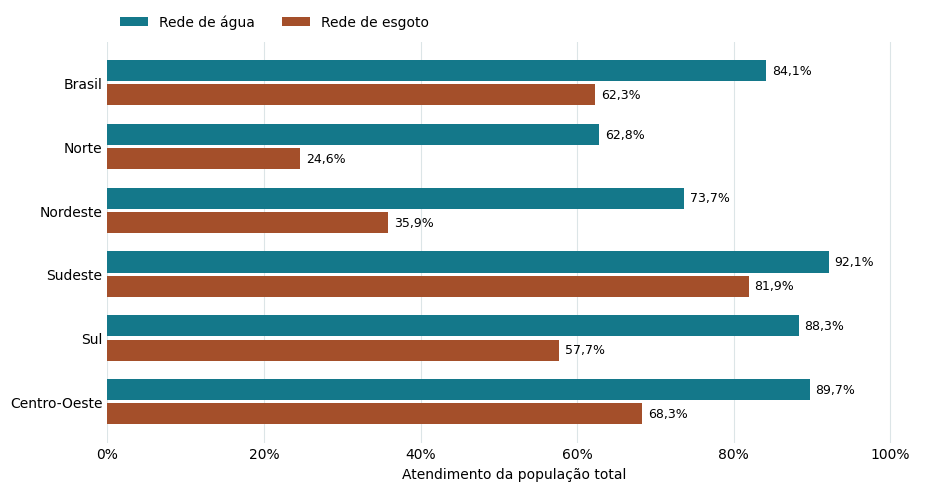

In [6]:
totais = ["agua_total_pct", "esgoto_total_pct", "diferenca_total_pp"]
display(territorios.loc[territorios["nivel"].ne("UF"), ["territorio", *totais, "esgoto_tratado_pct"]])
figura = an.grafico_regioes(territorios)
display(figura)
plt.close(figura)

A diferença nacional é de **21,84 p.p.** O Norte tem o maior valor entre as macrorregiões (**38,16 p.p.**), seguido pelo Nordeste (**37,80 p.p.**) e pelo Sul (**30,60 p.p.**). A menor está no Sudeste (**10,17 p.p.**).

### 2.1 As 27 UFs e a distância até as metas de 2033

In [7]:
display(an.ranking_ufs(territorios))
display(pd.Series(an.resumo_ufs(territorios), name="Valor").round(3).to_frame())

,sigla,territorio,regiao,agua_total_pct,esgoto_total_pct,diferenca_total_pp,falta_agua_pp,falta_esgoto_pp,esgoto_tratado_pct
0,AP,Amapá,Norte,71.29,9.29,62.00,27.71,80.71,100.00
1,SC,Santa Catarina,Sul,89.56,35.89,53.67,9.44,54.11,98.23
2,AL,Alagoas,Nordeste,73.27,22.32,50.95,25.73,67.68,86.05
3,AM,Amazonas,Norte,81.28,32.26,49.02,17.72,57.74,92.18
4,TO,Tocantins,Norte,84.23,37.02,47.21,14.77,52.98,99.57
5,RN,Rio Grande do Norte,Nordeste,76.38,31.41,44.97,22.62,58.59,95.41
6,PE,Pernambuco,Nordeste,71.56,29.35,42.21,27.44,60.65,68.54
7,SE,Sergipe,Nordeste,93.74,51.63,42.11,5.26,38.37,94.94
8,RO,Rondônia,Norte,53.51,13.28,40.23,45.49,76.72,89.21
9,CE,Ceará,Nordeste,72.17,32.60,39.57,26.83,57.40,93.12


,Valor
ufs_na_meta_agua,0.00
ufs_na_meta_esgoto,2.00
ufs_esgoto_abaixo_de_50,15.00
diferenca_mediana_pp,33.58
diferenca_desvio_padrao_pp,15.56
amplitude_pp,57.92
pearson_entre_ufs,0.76


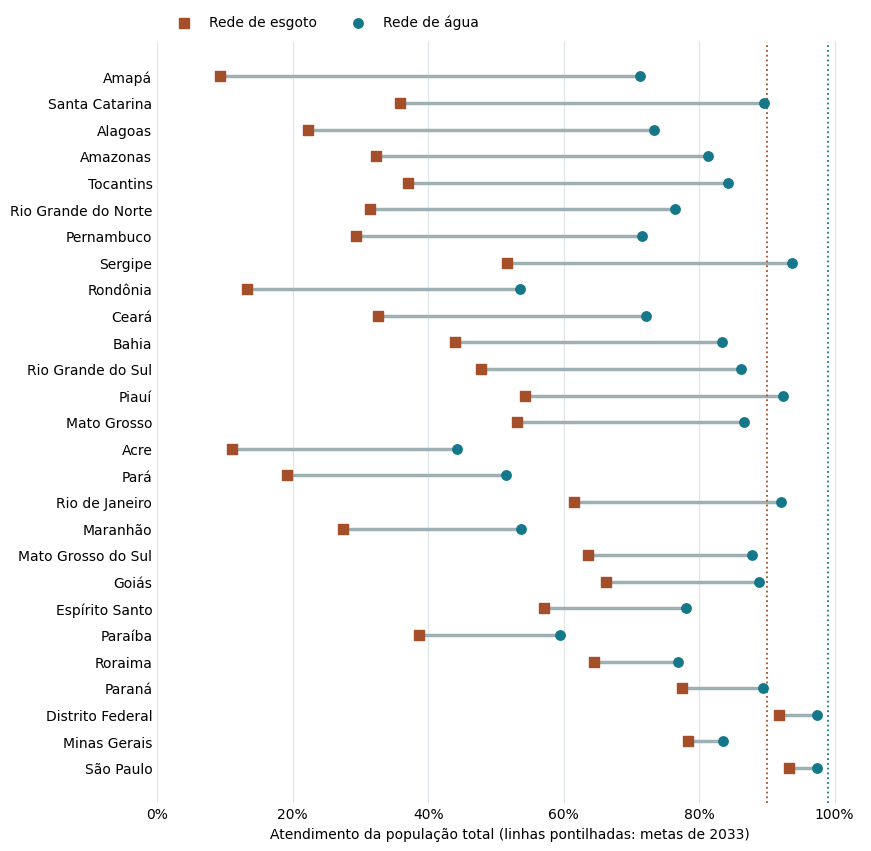

In [8]:
# No artigo este gráfico é interativo (Plotly), com menu de ordenação.
# Aqui vai a versão estática, que também aparece no visualizador do GitHub.
ufs = an.ranking_ufs(territorios).sort_values("diferenca_total_pp")
fig, ax = plt.subplots(figsize=(8.6, 8.4), layout="constrained")
ax.hlines(ufs["territorio"], ufs["esgoto_total_pct"], ufs["agua_total_pct"], color="#9fb0b5", linewidth=2.5)
ax.scatter(ufs["esgoto_total_pct"], ufs["territorio"], color=an.ESGOTO, marker="s", s=42, label="Rede de esgoto", zorder=3)
ax.scatter(ufs["agua_total_pct"], ufs["territorio"], color=an.AGUA, s=46, label="Rede de água", zorder=3)
ax.axvline(an.META_ESGOTO, color=an.ESGOTO, linestyle=":", linewidth=1.3)
ax.axvline(an.META_AGUA, color=an.AGUA, linestyle=":", linewidth=1.3)
an.eixo_percentual(ax)
ax.set_xlabel("Atendimento da população total (linhas pontilhadas: metas de 2033)")
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1), ncols=2)
display(fig)
plt.close(fig)

Entre as UFs, a diferença vai de **4,08 p.p.** (São Paulo) a **62,00 p.p.** (Amapá), com mediana de 33,58 p.p. e desvio-padrão de 15,56 p.p. Santa Catarina tem a segunda maior (53,67 p.p.).

Nenhuma UF alcança 99% em água. Só São Paulo e o Distrito Federal passam de 90% em esgoto, e 15 UFs estão abaixo de 50%. Diferença pequena não significa atendimento alto: na Paraíba ela é de 20,84 p.p., com 59,45% em água e 38,61% em esgoto.

A coluna `esgoto_tratado_pct` lembra que coleta não é tratamento. No Brasil, 85,16% do esgoto coletado é tratado. Em Minas Gerais, terceira maior taxa de coleta, são 62,04%.

## 3. RQ2 — Atendimento urbano e rural

Dentro de cada módulo, calculamos o hiato `urbano − rural`. Cada taxa usa a população de referência do próprio recorte.

,territorio,agua_urbana_pct,agua_rural_pct,hiato_agua_pp,esgoto_urbana_pct,esgoto_rural_pct,hiato_esgoto_pp
0,Brasil,92.32,22.88,69.44,68.44,4.75,63.69
1,Norte,74.93,13.27,61.66,27.68,1.05,26.63
2,Nordeste,85.34,29.86,55.48,43.45,2.81,40.64
3,Sudeste,96.18,21.42,74.76,85.80,11.23,74.57
4,Sul,97.51,17.22,80.29,63.32,2.74,60.58
5,Centro-Oeste,96.95,9.44,87.51,73.28,2.73,70.55


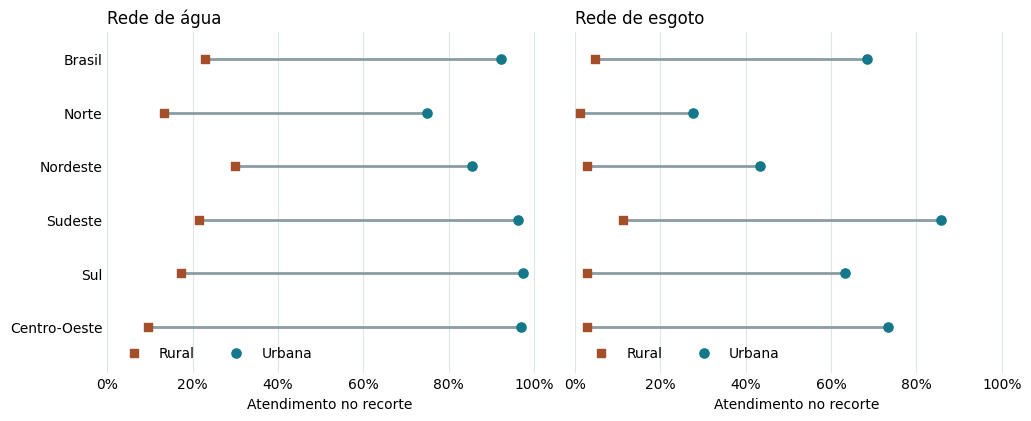

In [9]:
recortes = [
    "territorio", "agua_urbana_pct", "agua_rural_pct", "hiato_agua_pp",
    "esgoto_urbana_pct", "esgoto_rural_pct", "hiato_esgoto_pp",
]
display(territorios.loc[territorios["nivel"].ne("UF"), recortes])
figura = an.grafico_urbano_rural(territorios)
display(figura)
plt.close(figura)

No Brasil, o hiato é de **69,44 p.p.** em água (92,32% contra 22,88%) e de **63,69 p.p.** em esgoto (68,44% contra 4,75%). O maior hiato regional em água está no Centro-Oeste (**87,51 p.p.**). Em esgoto, o maior é o do Sudeste (**74,57 p.p.**) e o menor é o do Norte (26,63 p.p.), onde os dois percentuais são baixos.

### 3.1 O recorte rural nas UFs

,sigla,regiao,agua_urbana_pct,agua_rural_pct,hiato_agua_pp,esgoto_urbana_pct,esgoto_rural_pct,hiato_esgoto_pp
0,MS,Centro-Oeste,99.27,1.81,97.46,71.87,0.00,71.87
1,GO,Centro-Oeste,94.97,1.94,93.03,70.91,0.05,70.86
2,RR,Norte,95.45,9.21,86.24,80.42,0.00,80.42
3,MT,Centro-Oeste,97.46,12.49,84.97,57.57,0.00,57.57
4,TO,Norte,98.11,14.05,84.06,43.39,0.00,43.39
5,PR,Sul,98.39,16.92,81.47,86.39,3.92,82.47
6,ES,Sudeste,89.33,9.03,80.30,65.54,4.74,60.80
7,SC,Sul,98.61,18.91,79.70,40.12,0.78,39.34
8,RS,Sul,95.77,16.37,79.40,50.52,2.64,47.88
9,MG,Sudeste,92.11,17.64,74.47,86.33,12.70,73.63


,Valor
ufs_esgoto_rural_abaixo_de_5,21.00
ufs_esgoto_rural_zero,6.00
ufs_agua_rural_acima_de_50,3.00
agua_rural_mediana,16.37
esgoto_rural_mediana,2.27


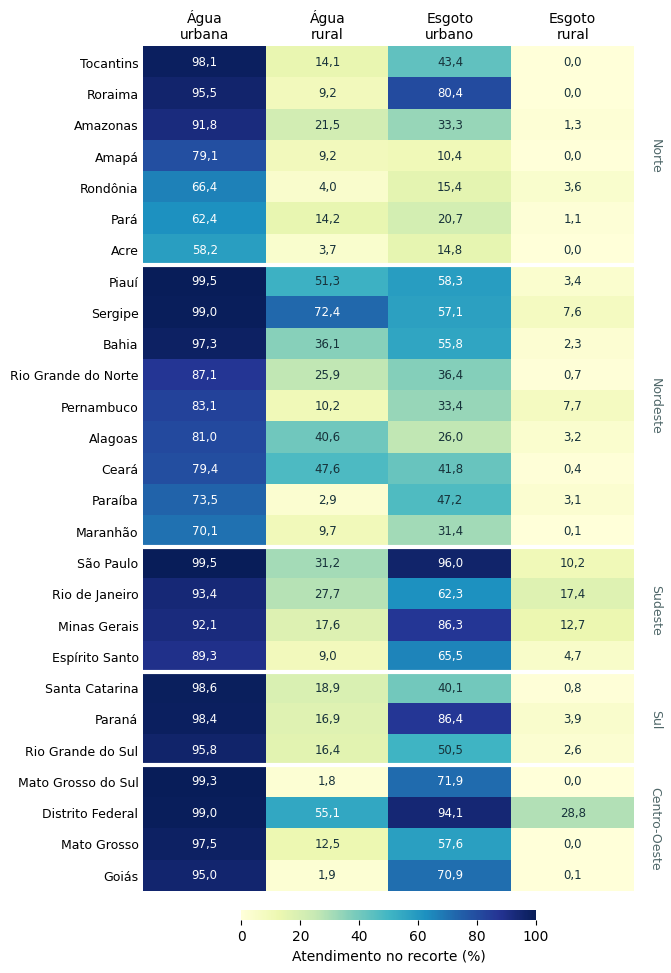

In [10]:
display(an.hiatos_ufs(territorios))
display(pd.Series(an.resumo_rural(territorios), name="Valor").round(2).to_frame())
figura = an.grafico_calor_ufs(territorios)
display(figura)
plt.close(figura)

A coleta rural por rede fica abaixo de 5% em **21 das 27 UFs** e é zero em seis. Só três UFs atendem mais da metade da população rural com rede de água: Sergipe (72,40%), Distrito Federal (55,06%) e Piauí (51,32%). O mapa de calor também mostra que a distância entre água e esgoto já existe dentro das cidades: a coluna de água urbana é escura em quase todo o país, e a de esgoto urbano varia de 10,4% (Amapá) a 96,0% (São Paulo).

O recorte mede redes. Poços, cisternas e fossas, comuns em áreas de baixa densidade, ficam de fora.

## 4. RQ3 — Dispersão e associação municipal

Para cada município pareado, usamos a diferença com sinal. O intervalo interquartil é `Q3 − Q1`. Valores abaixo de `Q1 − 1,5 × IQR` ou acima de `Q3 + 1,5 × IQR` ficam sinalizados como extremos (critério de Tukey). Pearson mede a associação linear e Spearman, a associação por postos.

,agua_total_pct,esgoto_total_pct,diferenca_total_pp
count,2710.00,2710.00,2710.00
mean,76.74,57.30,19.44
std,19.43,29.88,26.42
min,0.00,0.00,-66.20
25%,64.66,33.10,0.69
50%,81.38,59.94,10.82
75%,92.73,84.46,35.02
max,100.00,100.00,99.75


,Valor
n,2710.00
media_pp,19.44
mediana_pp,10.81
desvio_padrao_pp,26.42
q1_pp,0.69
q3_pp,35.02
iqr_pp,34.34
assimetria,0.74
pearson,0.49
spearman,0.54


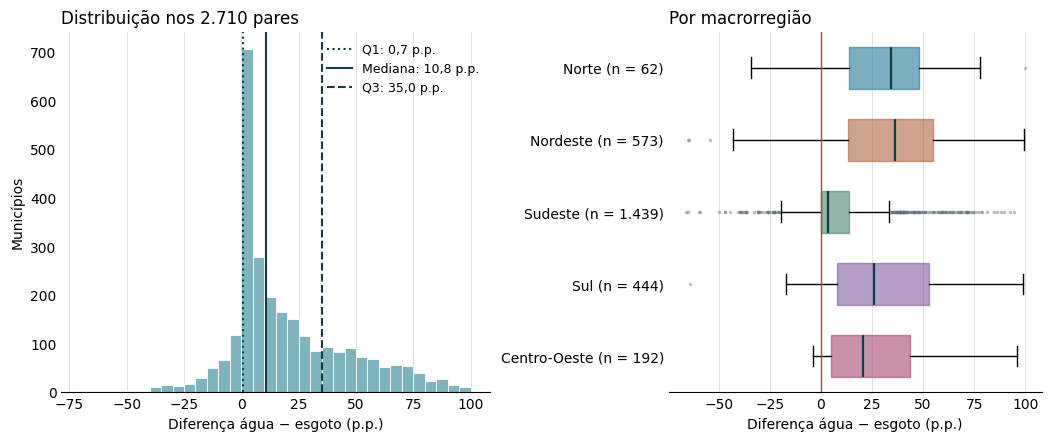

In [11]:
pares = an.pares_validos(municipios)
display(pares[["agua_total_pct", "esgoto_total_pct", "diferenca_total_pp"]].describe().round(2))
display(pd.Series(an.diagnostico(pares), name="Valor").round(3).to_frame())
figura = an.grafico_distribuicao(pares)
display(figura)
plt.close(figura)

A diferença mediana é de **10,82 p.p.** (Q1 = 0,69 e Q3 = 35,03 p.p.), com desvio-padrão de **26,42 p.p.** A média (19,44 p.p.) fica acima da mediana e a assimetria é positiva (0,74): muitos municípios perto de zero e uma cauda longa de municípios com muita água e pouco esgoto.

### 4.1 Por região e por faixa de diferença

In [12]:
display(an.resumo_municipal(pares).round(3))
faixas = an.faixas(pares)
display(faixas)
display(faixas.div(faixas.sum(axis=1), axis=0).mul(100).round(1))

,n,mediana,q1,q3,desvio_padrao,esgoto_maior,pearson,spearman
regiao,,,,,,,,
Norte,62,34.09,13.92,47.87,25.69,2,0.41,0.41
Nordeste,573,36.25,13.41,54.95,30.01,71,0.15,0.14
Sudeste,1439,3.55,0.00,13.62,18.42,238,0.68,0.72
Sul,444,25.79,8.07,52.84,28.05,20,0.39,0.41
Centro-Oeste,192,20.59,4.83,43.56,24.67,3,0.39,0.36


diferenca_total_pp,Esgoto acima (< −5),Próximos (−5 a 5),5 a 25,25 a 50,Acima de 50
regiao,,,,,
Norte,2,6,15,24,15
Nordeste,60,46,121,163,183
Sudeste,147,641,464,130,57
Sul,7,85,126,107,119
Centro-Oeste,0,48,63,41,40
Brasil,216,826,789,465,414


diferenca_total_pp,Esgoto acima (< −5),Próximos (−5 a 5),5 a 25,25 a 50,Acima de 50
regiao,,,,,
Norte,3.20,9.70,24.20,38.70,24.20
Nordeste,10.50,8.00,21.10,28.40,31.90
Sudeste,10.20,44.50,32.20,9.00,4.00
Sul,1.60,19.10,28.40,24.10,26.80
Centro-Oeste,0.00,25.00,32.80,21.40,20.80
Brasil,8.00,30.50,29.10,17.20,15.30


No Sudeste, metade dos municípios tem diferença de até 3,55 p.p. No Nordeste e no Sul, a mediana passa de 25 p.p. No conjunto, 30,5% dos municípios têm os dois indicadores a até 5 p.p. um do outro e 15,3% têm mais de 50 p.p. de distância.

### 4.2 Associação entre os dois indicadores

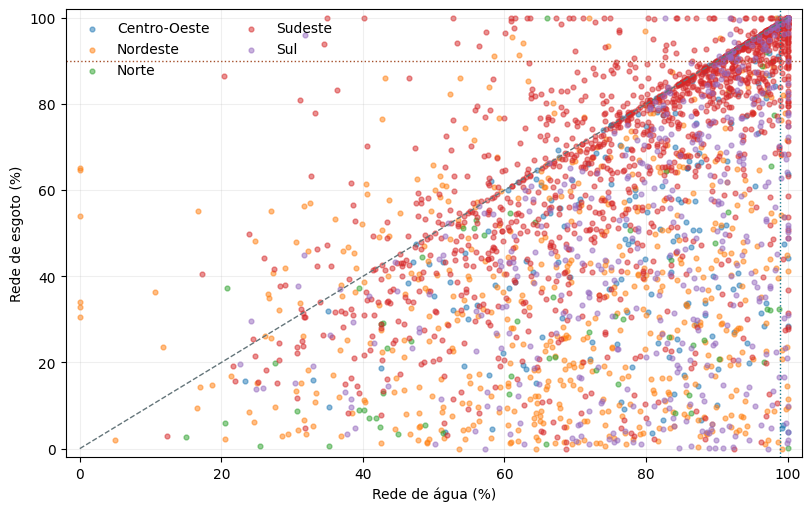

In [13]:
# No HTML do artigo o gráfico é interativo. Aqui, a tabela e a figura estática
# também ficam visíveis no visualizador de notebooks do GitHub.
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
for regiao, grupo in pares.groupby("regiao"):
    ax.scatter(grupo["agua_total_pct"], grupo["esgoto_total_pct"], label=regiao, s=12, alpha=0.5)
ax.plot([0, 100], [0, 100], "--", color="#64757a", linewidth=1)
ax.set(xlim=(-2, 102), ylim=(-2, 102), xlabel="Rede de água (%)", ylabel="Rede de esgoto (%)")
ax.legend(frameon=False, loc="upper left", ncols=2)
ax.axvline(an.META_AGUA, color=an.AGUA, linestyle=":", linewidth=1)
ax.axhline(an.META_ESGOTO, color=an.ESGOTO, linestyle=":", linewidth=1)
ax.grid(alpha=0.2)
display(fig)
plt.close(fig)

Pearson (**0,493**) e Spearman (**0,541**) indicam associação positiva moderada. Ela é forte no Sudeste (Pearson de 0,676) e quase nula no Nordeste (0,149). Na amostra, 219 municípios têm 99% ou mais em água, 462 têm 90% ou mais em esgoto e 130 cumprem as duas condições.

### 4.3 Extremos e municípios com mais esgoto que água

In [14]:
inferior, superior = an.limites_iqr(pares["diferenca_total_pp"])
print(f"Limites de Tukey: {inferior:.2f} e {superior:.2f} p.p.")
display(an.extremos(pares))
display(pd.Series(an.prestadores_distintos(pares), name="Prestadores de naturezas distintas (%)").round(1).to_frame())

Limites de Tukey: -50.81 e 86.53 p.p.


,municipio,uf,agua_total_pct,esgoto_total_pct,diferenca_total_pp,prestador_agua,prestador_esgoto
238,Ulianópolis,PA,100.00,0.25,99.75,Autarquia,Autarquia
571,Barra D Alcântara,PI,99.19,0.02,99.17,Município,Município
4428,Imbé,RS,99.99,1.23,98.76,Empresa privada,Empresa privada
4470,Mato Leitão,RS,100.00,2.00,98.00,Associação privada,Município
4331,Charqueadas,RS,97.19,0.01,97.18,Empresa privada,Empresa privada
2144,Cuparaque,MG,20.33,86.53,-66.20,Sociedade de economia mista,Município
1105,Riacho de Santo Antônio,PB,0.00,65.07,-65.07,Sociedade de economia mista,Mais de um tipo
2050,Caparaó,MG,34.99,100.00,-65.01,Sociedade de economia mista,Município
1371,Flexeiras,AL,0.00,64.68,-64.68,Sociedade de economia mista,Município
4524,Pedras Altas,RS,31.86,96.05,-64.19,Empresa privada,Empresa privada


,Prestadores de naturezas distintas (%)
todos_pct,21.40
esgoto_maior_pct,73.70
demais_pct,14.10


O critério sinaliza 48 municípios (40 acima e 8 abaixo). Todos ficam na análise, porque os valores estão na faixa válida.

Em **334 municípios** o esgoto supera a água. Em 73,7% deles, água e esgoto têm prestadores de naturezas diferentes, contra 14,1% nos demais. O caso típico é uma companhia estadual na água e a prefeitura no esgoto. Como cada prestador informa o seu módulo, esses casos sugerem diferença de declaração entre os módulos, e não municípios com esgoto e sem água.

### 4.4 Natureza do prestador e capitais

In [15]:
display(an.por_prestador(pares).round(2))
display(an.capitais(pares))

,n,agua_mediana,esgoto_mediana,diferenca_mediana
prestador_agua,,,,
Sociedade de economia mista,1337,72.85,51.93,13.71
Empresa privada,605,91.47,77.42,9.16
Autarquia,299,92.12,81.51,4.14
Município,268,89.21,80.36,0.31
Mais de um tipo,155,74.99,21.12,45.86
Empresa pública,45,59.36,40.54,13.59


,municipio,uf,agua_total_pct,esgoto_total_pct,diferenca_total_pp
0,Manaus,AM,97.13,32.35,64.78
1,Belém,PA,88.18,25.27,62.91
2,Macapá,AP,76.05,14.94,61.11
3,Maceió,AL,85.70,33.53,52.17
4,São Luís,MA,89.23,41.85,47.38
5,Natal,RN,90.51,45.88,44.63
6,Teresina,PI,94.81,55.46,39.35
7,Recife,PE,78.93,40.28,38.65
8,Florianópolis,SC,96.67,67.66,29.01
9,Porto Alegre,RS,100.00,72.35,27.65


Municípios atendidos por autarquias e pela administração direta têm as menores diferenças medianas. Nos atendidos por sociedades de economia mista, a mediana é de 13,71 p.p. A tabela descreve grupos e não controla região nem porte, então não mede o efeito do modelo de prestação.

Entre as 27 capitais, três têm 99% ou mais em água e 90% ou mais em esgoto (São Paulo, Curitiba e Goiânia), e nove têm menos de 50% em esgoto.

## 5. Conclusão

- **RQ1** — A diferença entre água e esgoto é de 21,84 p.p. no Brasil e varia de 10,17 a 38,16 p.p. entre regiões e de 4,08 a 62,00 p.p. entre UFs. Nenhuma UF alcança 99% em água e duas passam de 90% em esgoto.
- **RQ2** — O urbano supera o rural em 69,44 p.p. em água e 63,69 p.p. em esgoto. A coleta rural por rede fica abaixo de 5% em 21 UFs.
- **RQ3** — Nos 2.710 pares, a mediana é de 10,82 p.p., com desvio-padrão de 26,42 p.p. A associação é positiva e moderada, forte no Sudeste e quase nula no Nordeste.

**Limites.** A amostra pareada cobre 52,6% dos municípios e se concentra no Sudeste. O recorte mede redes e coleta, sem soluções individuais nem tratamento. Os dados são declarados pelos prestadores e os módulos têm populações de referência distintas. Há um único ano de referência, sem medida de evolução ou causa.

[Artigo e gráficos interativos](https://gdaflon.github.io/lasalle/projeto-saneamento-sinisa/) · [Código e dicionário](https://github.com/GDaflon/lasalle/tree/main/linguagens-de-programacao/projeto-saneamento-sinisa)